In [1]:
import geopandas as gpd
import matplotlib.pyplot as plt

In [2]:
cities = gpd.read_file("data/puget_sound_cities.geojson")

study_names = ["Federal Way", "Kent", "Auburn", "Renton", "Tukwila"]
study = cities[cities["NAME"].isin(study_names)]
study[["NAME", "geometry"]]

,NAME,geometry
3,Tukwila,"POLYGON ((-122.31846 47.53177, -122.31826 47.5..."
7,Auburn,"POLYGON ((-122.28058 47.31432, -122.28046 47.3..."
8,Federal Way,"POLYGON ((-122.42321 47.32402, -122.41559 47.3..."
9,Renton,"MULTIPOLYGON (((-122.23145 47.49004, -122.2314..."
11,Kent,"MULTIPOLYGON (((-122.01634 47.363, -122.01633 ..."


In [3]:
flood = gpd.read_file("data/53033C_20260923/S_FLD_HAZ_AR.shp")
print(len(flood), "flood zone polygons")
print(flood.crs)
flood.head()

5617 flood zone polygons
EPSG:4269


,DFIRM_ID,VERSION_ID,FLD_AR_ID,STUDY_TYP,FLD_ZONE,ZONE_SUBTY,SFHA_TF,STATIC_BFE,V_DATUM,DEPTH,LEN_UNIT,VELOCITY,VEL_UNIT,AR_REVERT,AR_SUBTRV,BFE_REVERT,DEP_REVERT,DUAL_ZONE,SOURCE_CIT,geometry
0,53033C,1.1.1.0,53033C_1,NP,A,NaN,T,-9999.0,NaN,-9999.0,NaN,-9999.0,None,None,None,-9999.0,-9999.0,None,53033C_BASE1,"POLYGON ((-121.51717 47.12216, -121.51727 47.1..."
1,53033C,1.1.1.0,53033C_85,NP,A,NaN,T,-9999.0,NaN,-9999.0,NaN,-9999.0,None,None,None,-9999.0,-9999.0,None,53033C_BASE1,"POLYGON ((-121.75 47.16363, -121.74861 47.1637..."
2,53033C,1.1.1.0,53033C_138,NP,A,NaN,T,-9999.0,NaN,-9999.0,NaN,-9999.0,None,None,None,-9999.0,-9999.0,None,53033C_BASE1,"POLYGON ((-121.95335 47.15707, -121.95411 47.1..."
3,53033C,1.1.1.0,53033C_140,NP,A,NaN,T,-9999.0,NaN,-9999.0,NaN,-9999.0,None,None,None,-9999.0,-9999.0,None,53033C_BASE1,"POLYGON ((-122.00335 47.1875, -122.00344 47.18..."
4,53033C,1.1.1.0,53033C_141,NP,A,NaN,T,-9999.0,NaN,-9999.0,NaN,-9999.0,None,None,None,-9999.0,-9999.0,None,53033C_BASE1,"POLYGON ((-121.9991 47.1875, -121.99441 47.187..."


In [4]:
flood["FLD_ZONE"].value_counts()

FLD_ZONE
X                    3118
AE                   1989
VE                    282
A                     111
AH                     78
AO                     31
D                       6
AREA NOT INCLUDED       1
OPEN WATER              1
Name: count, dtype: int64

In [5]:
study = study.to_crs(2927)
flood = flood.to_crs(2927)

In [6]:
sfha_zones = ["A", "AE", "AH", "AO", "VE"]
zone_100 = flood[flood["FLD_ZONE"].isin(sfha_zones)]
zone_500 = flood[flood["ZONE_SUBTY"] == "0.2 PCT ANNUAL CHANCE FLOOD HAZARD"]

print(len(zone_100), "polygons in the 100-year floodplain (SFHA)")
print(len(zone_500), "polygons in the 500-year floodplain")

2491 polygons in the 100-year floodplain (SFHA)
2433 polygons in the 500-year floodplain


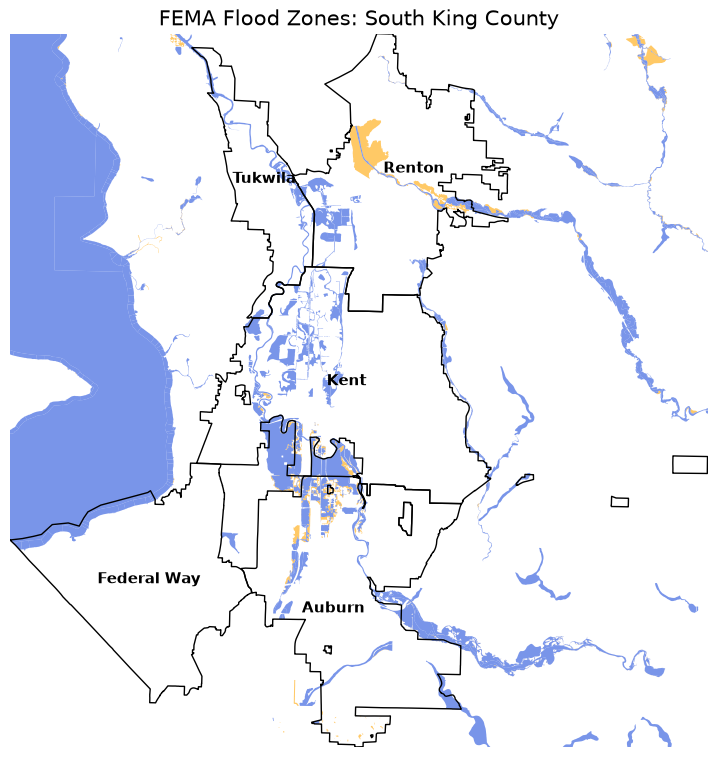

In [7]:
fig, ax = plt.subplots(figsize=(9, 11))

zone_500.plot(ax=ax, color="orange", alpha=0.6)
zone_100.plot(ax=ax, color="royalblue", alpha=0.7)
study.boundary.plot(ax=ax, color="black", linewidth=1)

for idx, row in study.iterrows():
    point = row.geometry.representative_point()
    ax.annotate(row["NAME"], xy=(point.x, point.y), ha="center", fontsize=11, fontweight="bold")

minx, miny, maxx, maxy = study.total_bounds
ax.set_xlim(minx, maxx)
ax.set_ylim(miny, maxy)

ax.set_title("FEMA Flood Zones: South King County", fontsize=15)
ax.set_axis_off()

In [8]:
study = study.copy()
study["city_sqmi"] = study.area / 27878400

sfha_pieces = gpd.overlay(study[["NAME", "geometry"]], zone_100[["geometry"]], how="intersection")
x500_pieces = gpd.overlay(study[["NAME", "geometry"]], zone_500[["geometry"]], how="intersection")

print(len(sfha_pieces), "100-year pieces inside the cities")
print(len(x500_pieces), "500-year pieces inside the cities")

439 100-year pieces inside the cities
214 500-year pieces inside the cities


In [9]:
sfha_pieces["sfha_sqmi"] = sfha_pieces.area / 27878400
x500_pieces["x500_sqmi"] = x500_pieces.area / 27878400

sfha_by_city = sfha_pieces.groupby("NAME")["sfha_sqmi"].sum()
x500_by_city = x500_pieces.groupby("NAME")["x500_sqmi"].sum()

sfha_by_city

NAME
Auburn         2.221250
Federal Way    1.267440
Kent           3.032357
Renton         1.459360
Tukwila        0.817386
Name: sfha_sqmi, dtype: float64

In [10]:
results = study[["NAME", "city_sqmi"]].set_index("NAME")
results["sfha_sqmi"] = sfha_by_city
results["x500_sqmi"] = x500_by_city
results = results.fillna(0)

results["pct_100yr"] = (results["sfha_sqmi"] / results["city_sqmi"] * 100).round(1)
results["pct_500yr"] = (results["x500_sqmi"] / results["city_sqmi"] * 100).round(1)

results = results.round(2).sort_values("pct_100yr", ascending=False)
results

,city_sqmi,sfha_sqmi,x500_sqmi,pct_100yr,pct_500yr
NAME,,,,,
Kent,34.42,3.03,0.12,8.8,0.4
Tukwila,9.60,0.82,0.00,8.5,0.0
Auburn,29.86,2.22,0.54,7.4,1.8
Renton,25.27,1.46,1.29,5.8,5.1
Federal Way,23.72,1.27,0.00,5.3,0.0


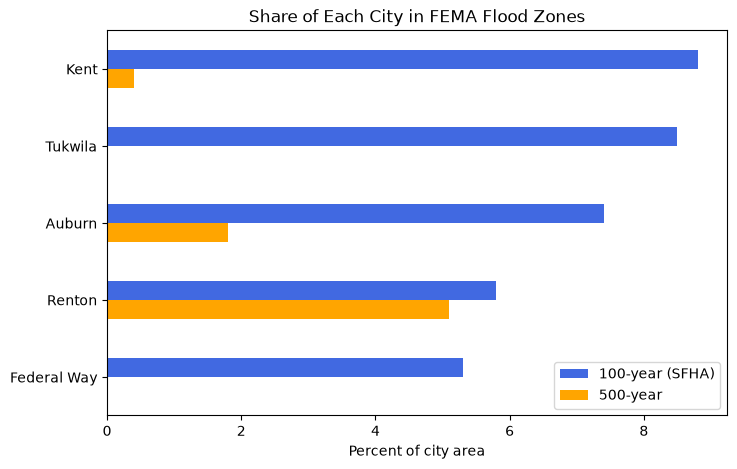

In [11]:
ax = results[["pct_100yr", "pct_500yr"]].plot.barh(figsize=(8, 5), color=["royalblue", "orange"])
ax.set_xlabel("Percent of city area")
ax.set_ylabel("")
ax.set_title("Share of Each City in FEMA Flood Zones")
ax.legend(["100-year (SFHA)", "500-year"])
ax.invert_yaxis()

In [12]:
results.to_csv("flood_by_city.csv")

In [13]:
study = study.copy()
study["city_sqmi"] = study.area / 27878400

sfha_pieces = gpd.overlay(study[["NAME", "geometry"]], zone_100[["geometry"]], how="intersection")
x500_pieces = gpd.overlay(study[["NAME", "geometry"]], zone_500[["geometry"]], how="intersection")

print(len(sfha_pieces), "100-year pieces inside the cities")
print(len(x500_pieces), "500-year pieces inside the cities")

439 100-year pieces inside the cities
214 500-year pieces inside the cities


In [14]:
sfha_pieces["sfha_sqmi"] = sfha_pieces.area / 27878400
x500_pieces["x500_sqmi"] = x500_pieces.area / 27878400

sfha_by_city = sfha_pieces.groupby("NAME")["sfha_sqmi"].sum()
x500_by_city = x500_pieces.groupby("NAME")["x500_sqmi"].sum()

sfha_by_city

NAME
Auburn         2.221250
Federal Way    1.267440
Kent           3.032357
Renton         1.459360
Tukwila        0.817386
Name: sfha_sqmi, dtype: float64

In [15]:
results = study[["NAME", "city_sqmi"]].set_index("NAME")
results["sfha_sqmi"] = sfha_by_city
results["x500_sqmi"] = x500_by_city
results = results.fillna(0)

results["pct_100yr"] = (results["sfha_sqmi"] / results["city_sqmi"] * 100).round(1)
results["pct_500yr"] = (results["x500_sqmi"] / results["city_sqmi"] * 100).round(1)

results = results.round(2).sort_values("pct_100yr", ascending=False)
results

,city_sqmi,sfha_sqmi,x500_sqmi,pct_100yr,pct_500yr
NAME,,,,,
Kent,34.42,3.03,0.12,8.8,0.4
Tukwila,9.60,0.82,0.00,8.5,0.0
Auburn,29.86,2.22,0.54,7.4,1.8
Renton,25.27,1.46,1.29,5.8,5.1
Federal Way,23.72,1.27,0.00,5.3,0.0


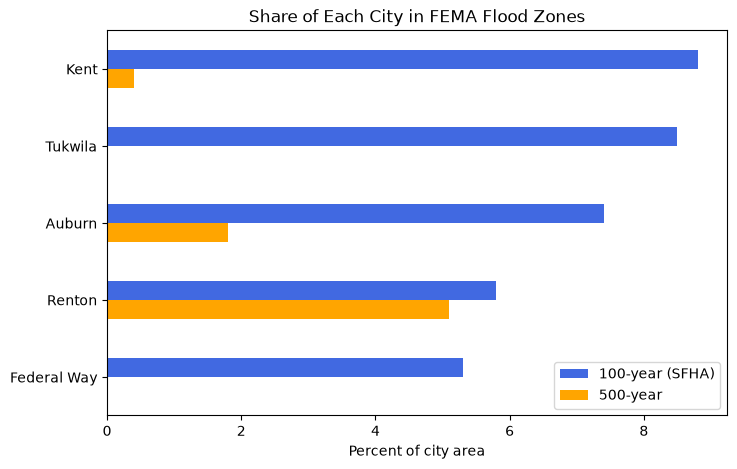

In [16]:
ax = results[["pct_100yr", "pct_500yr"]].plot.barh(figsize=(8, 5), color=["royalblue", "orange"])
ax.set_xlabel("Percent of city area")
ax.set_ylabel("")
ax.set_title("Share of Each City in FEMA Flood Zones")
ax.legend(["100-year (SFHA)", "500-year"])
ax.invert_yaxis()

In [17]:
results.to_csv("flood_by_city.csv")

In [18]:
flood[flood["FLD_ZONE"] == "X"]["ZONE_SUBTY"].value_counts()

ZONE_SUBTY
0.2 PCT ANNUAL CHANCE FLOOD HAZARD           2433
AREA OF MINIMAL FLOOD HAZARD                  582
AREA WITH REDUCED FLOOD RISK DUE TO LEVEE     103
Name: count, dtype: int64

In [19]:
zone_levee = flood[flood["ZONE_SUBTY"] == "AREA WITH REDUCED FLOOD RISK DUE TO LEVEE"]

levee_pieces = gpd.overlay(study[["NAME", "geometry"]], zone_levee[["geometry"]], how="intersection")
levee_pieces["levee_sqmi"] = levee_pieces.area / 27878400

results["levee_sqmi"] = levee_pieces.groupby("NAME")["levee_sqmi"].sum()
results = results.fillna(0)
results["pct_levee"] = (results["levee_sqmi"] / results["city_sqmi"] * 100).round(1)
results["pct_total"] = results["pct_100yr"] + results["pct_500yr"] + results["pct_levee"]

results = results.round(2).sort_values("pct_total", ascending=False)
results

,city_sqmi,sfha_sqmi,x500_sqmi,pct_100yr,pct_500yr,levee_sqmi,pct_levee,pct_total
NAME,,,,,,,,
Kent,34.42,3.03,0.12,8.8,0.4,1.52,4.4,13.6
Renton,25.27,1.46,1.29,5.8,5.1,0.01,0.0,10.9
Auburn,29.86,2.22,0.54,7.4,1.8,0.00,0.0,9.2
Tukwila,9.60,0.82,0.00,8.5,0.0,0.00,0.0,8.5
Federal Way,23.72,1.27,0.00,5.3,0.0,0.00,0.0,5.3


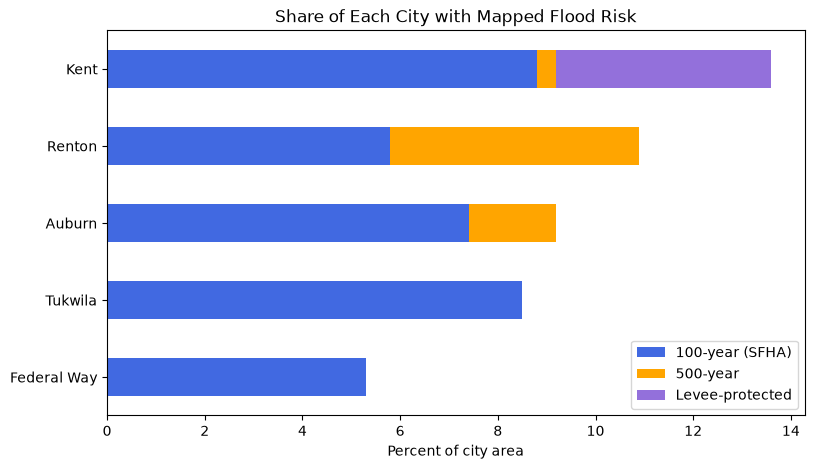

In [20]:
ax = results[["pct_100yr", "pct_500yr", "pct_levee"]].plot.barh(
    stacked=True, figsize=(9, 5), color=["royalblue", "orange", "mediumpurple"])
ax.set_xlabel("Percent of city area")
ax.set_ylabel("")
ax.set_title("Share of Each City with Mapped Flood Risk")
ax.legend(["100-year (SFHA)", "500-year", "Levee-protected"])
ax.invert_yaxis()
plt.savefig("flood_by_city_chart.png", dpi=150, bbox_inches="tight")

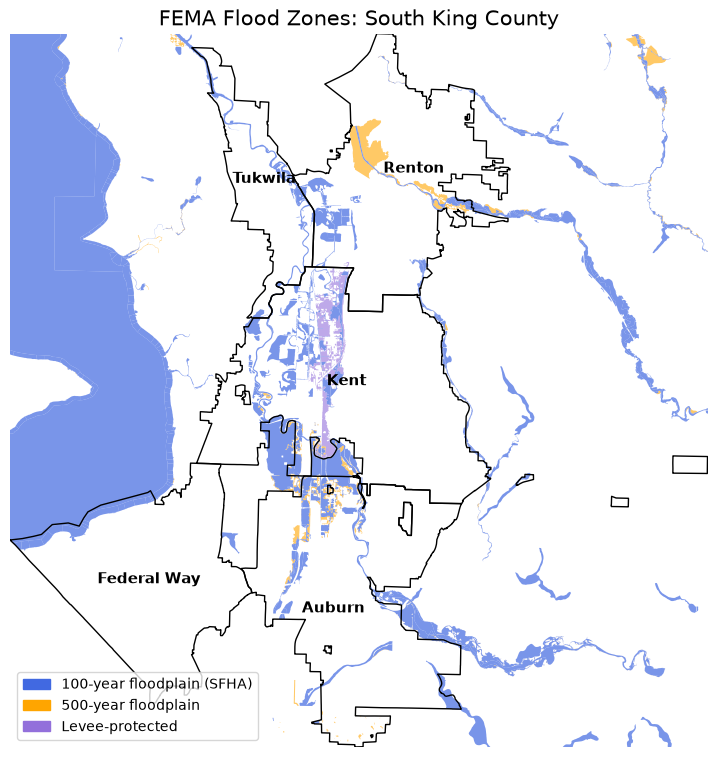

In [21]:
fig, ax = plt.subplots(figsize=(9, 11))

zone_levee.plot(ax=ax, color="mediumpurple", alpha=0.6)
zone_500.plot(ax=ax, color="orange", alpha=0.6)
zone_100.plot(ax=ax, color="royalblue", alpha=0.7)
study.boundary.plot(ax=ax, color="black", linewidth=1)

for idx, row in study.iterrows():
    point = row.geometry.representative_point()
    ax.annotate(row["NAME"], xy=(point.x, point.y), ha="center", fontsize=11, fontweight="bold")

minx, miny, maxx, maxy = study.total_bounds
ax.set_xlim(minx, maxx)
ax.set_ylim(miny, maxy)

from matplotlib.patches import Patch
legend_items = [Patch(color="royalblue", label="100-year floodplain (SFHA)"),
                Patch(color="orange", label="500-year floodplain"),
                Patch(color="mediumpurple", label="Levee-protected")]
ax.legend(handles=legend_items, loc="lower left")

ax.set_title("FEMA Flood Zones: South King County", fontsize=15)
ax.set_axis_off()
plt.savefig("flood_zones_map.png", dpi=150, bbox_inches="tight")

In [22]:
results.to_csv("flood_by_city.csv")

In [23]:
results

,city_sqmi,sfha_sqmi,x500_sqmi,pct_100yr,pct_500yr,levee_sqmi,pct_levee,pct_total
NAME,,,,,,,,
Kent,34.42,3.03,0.12,8.8,0.4,1.52,4.4,13.6
Renton,25.27,1.46,1.29,5.8,5.1,0.01,0.0,10.9
Auburn,29.86,2.22,0.54,7.4,1.8,0.00,0.0,9.2
Tukwila,9.60,0.82,0.00,8.5,0.0,0.00,0.0,8.5
Federal Way,23.72,1.27,0.00,5.3,0.0,0.00,0.0,5.3


In [24]:
bbox = tuple(study.to_crs(4326).total_bounds)
buildings = gpd.read_file("data/Washington.geojson", bbox=bbox)
print(len(buildings), "buildings in the study area box")

281152 buildings in the study area box


In [25]:
buildings = buildings.to_crs(2927)

points = buildings.copy()
points["geometry"] = buildings.representative_point()

points = gpd.sjoin(points, study[["NAME", "geometry"]], predicate="within").drop(columns="index_right")
print(len(points), "buildings inside the five cities")
points["NAME"].value_counts()

118009 buildings inside the five cities


NAME
Kent           33386
Renton         28869
Federal Way    25565
Auburn         24527
Tukwila         5662
Name: count, dtype: int64

In [26]:
import pandas as pd

zones_all = pd.concat([
    zone_100[["geometry"]].assign(zone="100-year"),
    zone_500[["geometry"]].assign(zone="500-year"),
    zone_levee[["geometry"]].assign(zone="Levee-protected"),
])
zones_all = gpd.GeoDataFrame(zones_all, crs=zone_100.crs)

in_zone = gpd.sjoin(points, zones_all, predicate="within")
in_zone = in_zone[~in_zone.index.duplicated()]
print(len(in_zone), "buildings in a mapped flood zone")

3276 buildings in a mapped flood zone


In [27]:
bldg = in_zone.groupby(["NAME", "zone"]).size().unstack(fill_value=0)
bldg = bldg.reindex(study["NAME"], fill_value=0)
bldg["total_in_zones"] = bldg.sum(axis=1)
bldg["all_buildings"] = points.groupby("NAME").size()
bldg["pct_buildings"] = (bldg["total_in_zones"] / bldg["all_buildings"] * 100).round(1)

bldg = bldg.sort_values("total_in_zones", ascending=False)
bldg

zone,100-year,500-year,Levee-protected,total_in_zones,all_buildings,pct_buildings
NAME,,,,,,
Renton,119,1301,1,1421,28869,4.9
Kent,502,36,762,1300,33386,3.9
Auburn,396,110,0,506,24527,2.1
Federal Way,27,0,0,27,25565,0.1
Tukwila,22,0,0,22,5662,0.4


In [28]:
bldg.to_csv("buildings_by_city.csv")

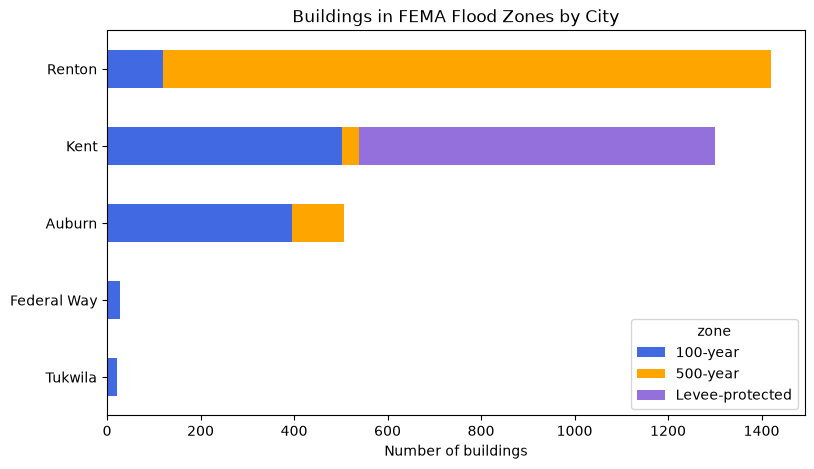

In [29]:
ax = bldg[["100-year", "500-year", "Levee-protected"]].plot.barh(
    stacked=True, figsize=(9, 5), color=["royalblue", "orange", "mediumpurple"])
ax.set_xlabel("Number of buildings")
ax.set_ylabel("")
ax.set_title("Buildings in FEMA Flood Zones by City")
ax.invert_yaxis()
plt.savefig("buildings_by_city_chart.png", dpi=150, bbox_inches="tight")